Cell 1 — Install Libraries

In [ ]:
!pip install spacy nltk pandas
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 43.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Cell 2 — Import Libraries

In [ ]:
import spacy
from spacy import displacy
import nltk
import pandas as pd

# Suppress pandas display limits for the table later
pd.set_option('display.max_rows', None)

Download/Load Public Corpus

In [ ]:
# Download the Brown Corpus from NLTK
nltk.download('brown')
from nltk.corpus import brown

[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Package brown is already up-to-date!


Explore the Corpus

In [ ]:
# Check out the categories and total number of files in the Brown corpus
categories = brown.categories()
total_files = len(brown.fileids())

print(f"Total number of documents in Brown Corpus: {total_files}")
print(f"Available text categories: {categories[:5]}...")

Total number of documents in Brown Corpus: 500
Available text categories: ['adventure', 'belles_lettres', 'editorial', 'fiction', 'government']...


Select One Document from the Corpus

In [ ]:
# Programmatically select the first document from the 'news' category
news_file_id = brown.fileids(categories='news')[0]

# The Brown corpus loads as a list of words, so we join the first 250 words into a single string document
words_list = brown.words(fileids=news_file_id)[:250]
document = " ".join(words_list)

Display the Selected Document

In [ ]:
print("--- Selected Document from Brown Corpus ---")
print(document)

--- Selected Document from Brown Corpus ---
The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place . The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted . The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was won by Mayor-nominate Ivan Allen Jr. . `` Only a relative handful of such reports was received '' , the jury said , `` considering the widespread interest in the election , the number of voters and the size of this city '' . The jury said it did find that many of Georgia's registration and election laws `` are outmoded or inadequate and often ambiguous '' . It recommend

Load Pretrained NER Model

In [ ]:
# Load the pretrained English model from spaCy
nlp = spacy.load("en_core_web_sm")

print("Pretrained spaCy NER model loaded successfully.")

Pretrained spaCy NER model loaded successfully.


Perform NER

In [ ]:
# Pass our selected document through the spaCy pipeline
doc = nlp(document)

print(f"Processed {len(doc)} tokens (words and punctuation).")

Processed 271 tokens (words and punctuation).


Display Extracted Named Entities

In [ ]:
# Extract the entity text, label, start character, and end character
entity_data = []
for ent in doc.ents:
    entity_data.append({
        "Entity": ent.text,
        "Label": ent.label_,
        "Start": ent.start_char,
        "End": ent.end_char
    })

# Convert the list of dictionaries into a clean Pandas DataFrame table
df_entities = pd.DataFrame(entity_data)

print("--- Extracted Named Entities ---")
display(df_entities)

--- Extracted Named Entities ---


,Entity,Label,Start,End
0,The Fulton County Grand Jury,ORG,0,28
1,Friday,DATE,34,40
2,Atlanta,GPE,61,68
3,the City Executive Committee,ORG,211,239
4,the City of Atlanta,GPE,323,342
5,September-October,DATE,403,420
6,Fulton Superior Court,ORG,451,472
7,Durwood Pye,PERSON,479,490
8,Ivan Allen Jr.,PERSON,606,620
9,Georgia,GPE,848,855


Visualize NER

In [ ]:
# Render the named entities directly in the text with color-coded highlighting
displacy.render(doc, style="ent", jupyter=True)

Final Result/Summary

In [ ]:
print("--- Notebook Summary ---")
print(f"Corpus Used: NLTK Brown Corpus (News Category)")
print(f"Total Entities Found: {len(doc.ents)}")
print("\nConclusion: The pretrained spaCy pipeline successfully identified and classified entities ")
print("such as organizations, locations, and dates from a real-world, publicly available news text ")
print("without requiring any manual data entry or model training.")

--- Notebook Summary ---
Corpus Used: NLTK Brown Corpus (News Category)
Total Entities Found: 14

Conclusion: The pretrained spaCy pipeline successfully identified and classified entities 
such as organizations, locations, and dates from a real-world, publicly available news text 
without requiring any manual data entry or model training.


Install and Import Visualization Libraries

In [ ]:
# Install libraries for plotting and word clouds
!pip install matplotlib seaborn wordcloud

# Import the newly installed libraries
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

Visualize Entity Label Frequencies (Bar Chart)

/tmp/ipykernel_697/2747239855.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 78 (N) missing from font(s) Noto Sans Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 117 (u) missing from font(s) Noto Sans Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dis

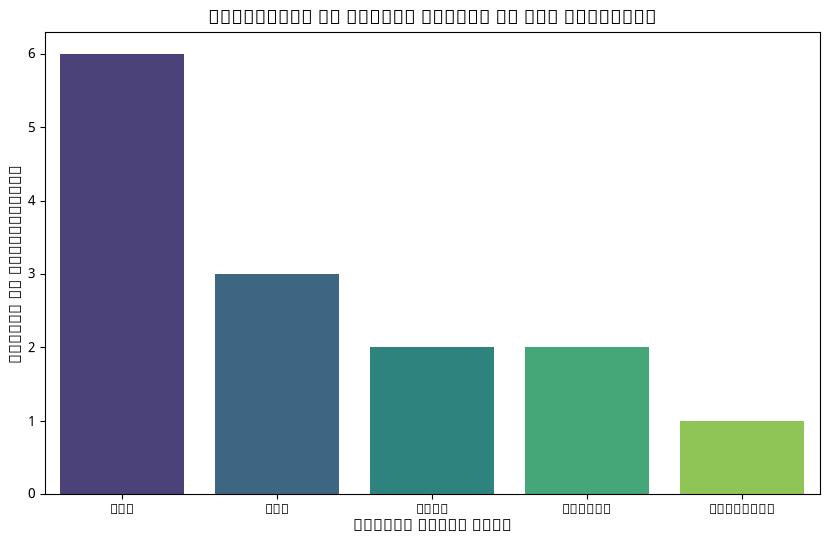

In [ ]:
# Set the size of the graph
plt.figure(figsize=(10, 6))

# Create a bar chart showing the count of each entity label (e.g., ORG, PERSON, DATE)
sns.countplot(
    data=df_entities,
    x='Label',
    palette='viridis',
    order=df_entities['Label'].value_counts().index # Sort from most to least frequent
)

# Add titles and labels
plt.title('Frequency of Entity Labels in the Document', fontsize=14)
plt.xlabel('Entity Label Type', fontsize=12)
plt.ylabel('Number of Occurrences', fontsize=12)

# Display the chart
plt.show()

# Part 2 — Second Input Type: URL
The assignment asks for two input types: a paragraph and a URL. Part 1 handled the paragraph (Brown corpus). This part fetches a live web page, extracts its paragraph text, and runs the same spaCy pipeline on it.

Install and Import Web-Scraping Libraries

In [ ]:
!pip install requests beautifulsoup4

import requests
from bs4 import BeautifulSoup
from collections import Counter

Define a Reusable Function: Fetch Text from a URL

In [ ]:
def fetch_text_from_url(url, max_chars=3000):
    """Download a web page and return the visible paragraph text."""
    headers = {"User-Agent": "Mozilla/5.0 (NER-assignment)"}
    response = requests.get(url, headers=headers, timeout=15)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    # Drop tags that never hold article text
    for tag in soup(["script", "style", "nav", "footer", "header", "table", "sup"]):
        tag.decompose()

    # Keep only <p> blocks; join them into one document
    paragraphs = [p.get_text(" ", strip=True) for p in soup.find_all("p")]
    text = " ".join(p for p in paragraphs if len(p) > 40)
    return text[:max_chars]

Fetch the URL Input

In [ ]:
url = "https://en.wikipedia.org/wiki/Indian_Space_Research_Organisation"

url_text = fetch_text_from_url(url)

print(f"Source URL : {url}")
print(f"Characters : {len(url_text)}")
print("\n--- First 800 characters of extracted text ---")
print(url_text[:800])

Perform NER on the URL Text

In [ ]:
doc_url = nlp(url_text)

df_url = pd.DataFrame([
    {"Entity": ent.text, "Label": ent.label_, "Start": ent.start_char, "End": ent.end_char}
    for ent in doc_url.ents
])

print(f"Total entities found in URL text: {len(doc_url.ents)}")
print(f"Distinct entity labels           : {sorted(df_url['Label'].unique())}")
display(df_url.head(30))

Visualize NER on the URL Text

In [ ]:
displacy.render(doc_url, style="ent", jupyter=True)

Entity Label Frequencies for the URL Text (Bar Chart)

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_url,
    x='Label',
    palette='viridis',
    order=df_url['Label'].value_counts().index
)
plt.title('Frequency of Entity Labels — URL Input', fontsize=14)
plt.xlabel('Entity Label Type', fontsize=12)
plt.ylabel('Number of Occurrences', fontsize=12)
plt.xticks(rotation=45)
plt.show()

Word Cloud of Named Entities from the URL Text

In [ ]:
entity_freq = Counter(ent.text for ent in doc_url.ents)

wc = WordCloud(width=1000, height=500, background_color='white', colormap='viridis')
wc.generate_from_frequencies(entity_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Most Frequent Named Entities — URL Input', fontsize=14)
plt.show()

# Part 3 — A Second Paragraph Input (User-Supplied)
A short hand-written paragraph that deliberately contains entity types the Brown excerpt did not have, such as MONEY, PERCENT, NORP, TIME and ORDINAL.

In [ ]:
user_paragraph = (
    "On 23 August 2023, ISRO's Chandrayaan-3 lander touched down near the Moon's south pole, "
    "making India the fourth nation to land on the lunar surface. The mission cost roughly "
    "Rs 615 crore, about $75 million, far less than NASA's Artemis programme. Prime Minister "
    "Narendra Modi watched the landing from Johannesburg, where he was attending the BRICS summit. "
    "Shares of Indian aerospace firms rose nearly 12% the next morning at 9:15 AM on the "
    "Bombay Stock Exchange. Apple later showcased the event on its iPhone 15 launch page, and "
    "the European Space Agency congratulated the Indian scientists in Bengaluru."
)

doc_para = nlp(user_paragraph)

df_para = pd.DataFrame([
    {"Entity": ent.text, "Label": ent.label_, "Explanation": spacy.explain(ent.label_)}
    for ent in doc_para.ents
])

print(f"Total entities found: {len(doc_para.ents)}")
display(df_para)

displacy.render(doc_para, style="ent", jupyter=True)

# Part 4 — NER with NLTK (`ne_chunk`) for Comparison
The lab slides describe the NLTK pipeline: `word_tokenize` → `pos_tag` → `ne_chunk`. This part runs it on the same user paragraph and compares the result with spaCy.

In [ ]:
import os
os.environ['NLTK_ALLOW_PROXIED_URLOPEN'] = '1'   # harmless on Colab; needed behind some proxies

for pkg in ['punkt', 'punkt_tab', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng',
            'maxent_ne_chunker', 'maxent_ne_chunker_tab', 'words']:
    nltk.download(pkg, quiet=True)

from nltk import word_tokenize, pos_tag, ne_chunk
from nltk.tree import Tree

# Step 1: tokenize   Step 2: POS-tag   Step 3: chunk named entities
tokens = word_tokenize(user_paragraph)
tagged = pos_tag(tokens)
tree   = ne_chunk(tagged)

nltk_entities = [
    (" ".join(tok for tok, _ in subtree.leaves()), subtree.label())
    for subtree in tree if isinstance(subtree, Tree)
]

df_nltk = pd.DataFrame(nltk_entities, columns=["Entity", "NLTK Label"])
print(f"NLTK found {len(df_nltk)} entities")
display(df_nltk)

Side-by-Side: spaCy vs NLTK on the Same Paragraph

In [ ]:
comparison = pd.DataFrame({
    "Library": ["spaCy (en_core_web_sm)", "NLTK (ne_chunk)"],
    "Entities found": [len(doc_para.ents), len(df_nltk)],
    "Distinct labels": [
        ", ".join(sorted(df_para['Label'].unique())),
        ", ".join(sorted(df_nltk['NLTK Label'].unique())),
    ],
})
display(comparison)

only_spacy = sorted(set(df_para["Label"]) - {"PERSON", "ORG", "GPE", "LOC", "FAC"})
print("Observation: NLTK's chunker only knows PERSON / ORGANIZATION / GPE / LOCATION / FACILITY.")
print(f"Label types found by spaCy that NLTK cannot produce: {only_spacy}")

# Part 5 — Combined Visual Summary Across All Inputs

In [ ]:
df_all = pd.concat([
    df_entities.assign(Input='Brown paragraph'),
    df_para[['Entity', 'Label']].assign(Input='User paragraph'),
    df_url[['Entity', 'Label']].assign(Input='URL (Wikipedia)'),
], ignore_index=True)

pivot = df_all.groupby(['Label', 'Input']).size().unstack(fill_value=0)
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]

pivot.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')
plt.title('Entity Label Distribution by Input Type', fontsize=14)
plt.xlabel('Entity Label')
plt.ylabel('Number of Occurrences')
plt.xticks(rotation=45)
plt.legend(title='Input')
plt.tight_layout()
plt.show()

display(pivot)

Final Conclusion

In [ ]:
print("--- Final Summary ---")
print(f"Inputs processed          : 3 (Brown corpus paragraph, user paragraph, live URL)")
print(f"Total entities (all inputs): {len(df_all)}")
print(f"Distinct entity types      : {df_all['Label'].nunique()} -> {sorted(df_all['Label'].unique())}")
print()
print("Conclusion: A pretrained spaCy NER pipeline was applied to both paragraph and URL inputs.")
print("Entities were demonstrated visually with displacy highlighting, bar charts, a word cloud")
print("and a stacked comparison. NLTK's ne_chunk was run on the same text for comparison and")
print("found fewer entity types than spaCy.")